In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files
files.upload()

Saving shop data.csv to shop data.csv


{'shop data.csv': b'age,income,gender,m_status,buys\r\n<25,high,male,single,no\r\n<25,high,male,married,no\r\n25-35,high,male,single,yes\r\n>35,medium,male,single,yes\r\n>35,low,female,single,yes\r\n>35,low,female,single,no\r\n25-35,low,female,married,yes\r\n<25,medium,male,married,no\r\n<25,low,female,single,yes\r\n>35,medium,female,married,yes\r\n<25,medium,female,single,yes\r\n25-35,medium,male,married,yes\r\n25-35,high,female,single,yes\r\n>35,medium,male,married,no\r\n<25,high,male,single,no\r\n<25,high,female,married,yes\r\n>35,medium,male,married,yes\r\n<25,high,female,single,yes\r\n25-35,medium,female,married,yes\r\n25-35,high,male,single,yes\r\n>35,medium,female,married,no\r\n<25,low,male,single,yes\r\n'}

In [3]:
df = pd.read_csv('shop data.csv')

In [4]:
df.head()

,age,income,gender,m_status,buys
0,<25,high,male,single,no
1,<25,high,male,married,no
2,25-35,high,male,single,yes
3,>35,medium,male,single,yes
4,>35,low,female,single,yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   age       22 non-null     object
 1   income    22 non-null     object
 2   gender    22 non-null     object
 3   m_status  22 non-null     object
 4   buys      22 non-null     object
dtypes: object(5)
memory usage: 1012.0+ bytes


In [6]:
df.describe()

,age,income,gender,m_status,buys
count,22,22,22,22,22
unique,3,3,2,2,2
top,<25,medium,male,single,yes
freq,9,9,11,12,15


In [7]:
df.isnull().sum()

,0
age,0
income,0
gender,0
m_status,0
buys,0


In [8]:
df.duplicated().sum()

np.int64(2)

In [9]:
df = df.drop_duplicates()

In [10]:
df.shape

(20, 5)

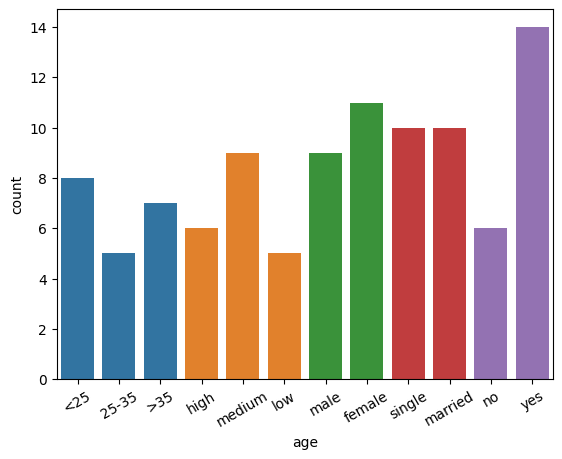

In [14]:
for col in df.columns:
  sns.countplot(data = df, x = col)
  plt.xticks(rotation = 30)

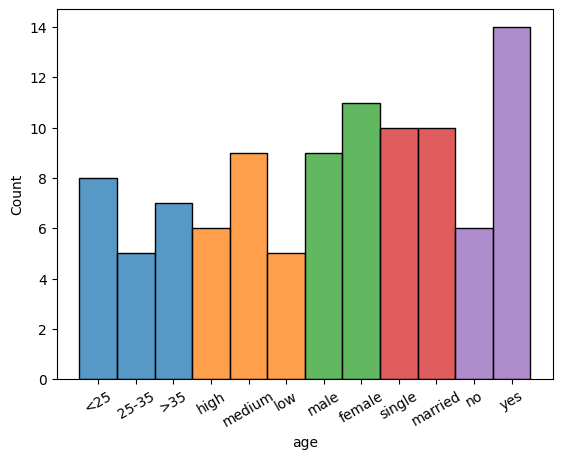

In [16]:
for col in df.columns:
  sns.histplot(data = df, x = col)
  plt.xticks(rotation = 30)

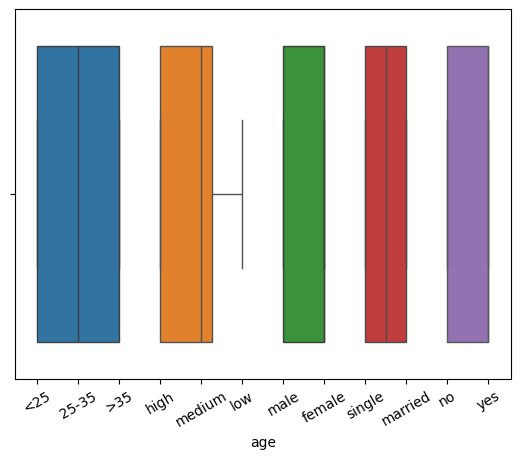

In [19]:
for col in df.columns:
  sns.boxplot(data = df, x = col)
  plt.xticks(rotation = 30)

In [21]:
for col in df.columns:
  print('\n')
  print(pd.crosstab(df[col], df['buys']))



buys   no  yes
age           
25-35   0    5
<25     3    5
>35     3    4


buys    no  yes
income         
high     2    4
low      1    4
medium   3    6


buys    no  yes
gender         
female   2    9
male     4    5


buys      no  yes
m_status         
married    4    6
single     2    8


buys  no  yes
buys         
no     6    0
yes    0   14


In [35]:
for col in df.columns:
  print('\n')
  print(df[col].value_counts())



age
<25      8
>35      7
25-35    5
Name: count, dtype: int64


income
medium    9
high      6
low       5
Name: count, dtype: int64


gender
female    11
male       9
Name: count, dtype: int64


m_status
single     10
married    10
Name: count, dtype: int64


buys
yes    14
no      6
Name: count, dtype: int64


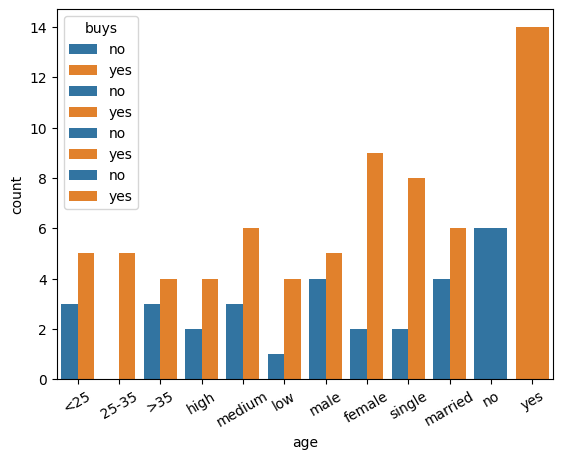

In [23]:
for col in df.columns:
  sns.countplot(data = df, x = col, hue = 'buys')
  plt.xticks(rotation = 30)

# EDA ends here


In [25]:
X = df.drop('buys', axis = 1)
y = df['buys']

In [26]:
from sklearn.model_selection import train_test_split

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42, stratify = y)

In [28]:
len(X_train), len(X_test)

(16, 4)

In [29]:
len(y_train), len(y_test)

(16, 4)

# Column transformer

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers = [(
        'cat', OneHotEncoder(handle_unknown = 'ignore'),
        X.columns
)]
)

In [48]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [49]:
from sklearn.preprocessing import StandardScaler

# pipeline

In [60]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])

knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors = 5))
])

dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('model', DecisionTreeClassifier(random_state=42))
])

# fit model

In [61]:
lr_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['age', 'income', 'gender', 'm_status'], dtype='object'))])),
                ('scaler', StandardScaler()),
                ('model', DecisionTreeClassifier(random_state=42))])

# prediction

In [62]:
y_pred_lr = lr_model.predict(X_test)
y_pred_knn = knn_model.predict(X_test)
y_pred_dt = dt_model.predict(X_test)

# metrices

In [63]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# accuracy

In [64]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)
knn_accuracy = accuracy_score(y_test, y_pred_knn)
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print('Logistic Regression Accuracy:', lr_accuracy)
print('KNN Accuracy:', knn_accuracy)
print('Decision Tree Accuracy:', dt_accuracy)

Logistic Regression Accuracy: 0.75
KNN Accuracy: 0.75
Decision Tree Accuracy: 1.0


# classification report

In [65]:
lr_report = classification_report(y_test, y_pred_lr)
knn_report = classification_report(y_test, y_pred_knn)
dt_report = classification_report(y_test, y_pred_dt)

print('Logistic Regression Classification Report:\n', lr_report)
print('KNN Classification Report:\n', knn_report)
print('Decision Tree Classification Report:\n', dt_report)

Logistic Regression Classification Report:
               precision    recall  f1-score   support

          no       0.00      0.00      0.00         1
         yes       0.75      1.00      0.86         3

    accuracy                           0.75         4
   macro avg       0.38      0.50      0.43         4
weighted avg       0.56      0.75      0.64         4

KNN Classification Report:
               precision    recall  f1-score   support

          no       0.00      0.00      0.00         1
         yes       0.75      1.00      0.86         3

    accuracy                           0.75         4
   macro avg       0.38      0.50      0.43         4
weighted avg       0.56      0.75      0.64         4

Decision Tree Classification Report:
               precision    recall  f1-score   support

          no       1.00      1.00      1.00         1
         yes       1.00      1.00      1.00         3

    accuracy                           1.00         4
   macro avg      

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

# confusion matrix

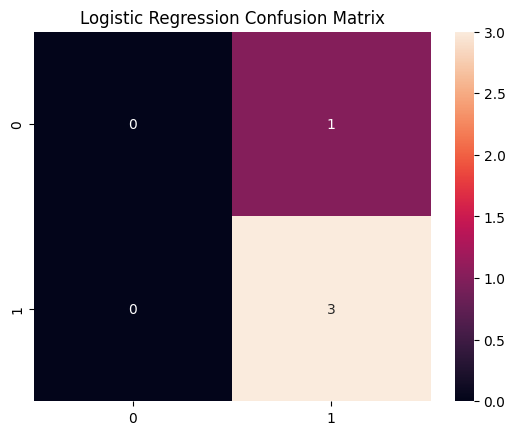

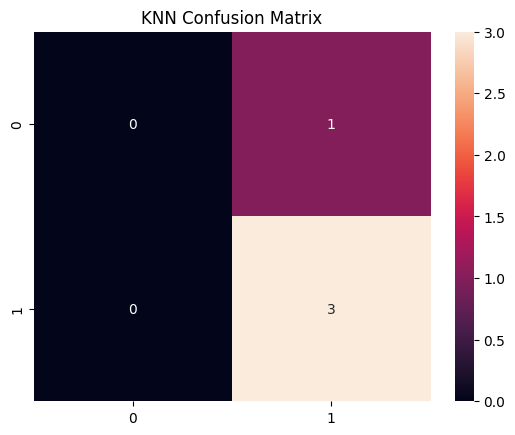

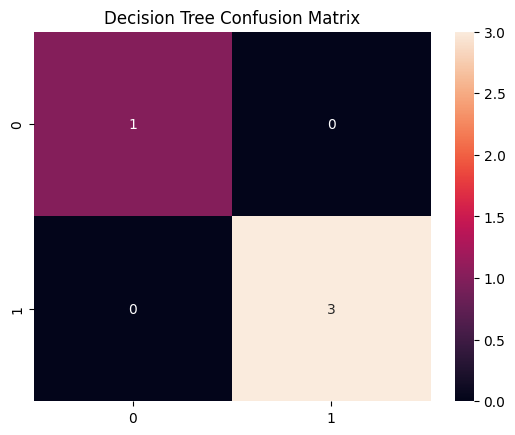

In [66]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_dt = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm_lr, annot = True)
plt.title('Logistic Regression Confusion Matrix')
plt.show()

sns.heatmap(cm_knn, annot = True)
plt.title('KNN Confusion Matrix')
plt.show()

sns.heatmap(cm_dt, annot = True)
plt.title('Decision Tree Confusion Matrix')
plt.show()

# prediction for new customer

In [69]:
new_customer = pd.DataFrame([{
    'age': '<25',
    'income': 'high',
    'gender': 'male',
    'm_status': 'single'
}])

print("Logistic Regression:",
      lr_model.predict(new_customer))

print("KNN:",
      knn_model.predict(new_customer))

print("Decision Tree:",
      dt_model.predict(new_customer))

Logistic Regression: ['yes']
KNN: ['yes']
Decision Tree: ['no']
